In [3]:
import pandas as pd
df = pd.read_csv("Dataset/Diabetes_data_og.csv")

df = df.drop_duplicates()
df

,Diabetes_012,HighBP,HighChol,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,Veggies,HvyAlcoholConsump,GenHlth,PhysHlth,DiffWalk,Sex,Age,Education
0,0,1,1,40,1,0,0,1,0,5,15,1,0,9,4
1,0,0,0,25,1,0,1,0,0,3,0,0,0,7,6
2,0,1,1,28,0,0,0,0,0,5,30,1,0,9,4
3,0,1,0,27,0,0,1,1,0,2,0,0,0,11,3
4,0,1,1,24,0,0,1,1,0,2,0,0,0,11,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253675,0,1,1,45,0,0,0,1,0,3,5,0,1,5,6
253676,2,1,1,18,0,0,0,0,0,4,0,1,0,11,2
253677,0,0,0,28,0,0,1,0,0,1,0,0,0,2,5
253678,0,1,0,23,0,0,0,1,0,3,0,0,1,7,5


Test accuracy: 0.699

             feature  rf_importance  permutation_importance  mutual_info  corr_with_target
             GenHlth         0.1180                  0.0369       0.0488            0.3022
                 BMI         0.2149                  0.0337       0.0292            0.2201
                 Age         0.1767                  0.0183       0.0218            0.1878
            HighChol         0.0498                  0.0127       0.0272            0.2181
        PhysActivity         0.0316                  0.0085       0.0174           -0.1199
              HighBP         0.0720                  0.0082       0.0421            0.2753
HeartDiseaseorAttack         0.0199                  0.0072       0.0112            0.1727
                 Sex         0.0381                  0.0069       0.0052            0.0282
            DiffWalk         0.0276                  0.0053       0.0218            0.2163
             Veggies         0.0277                  0.0045       0.

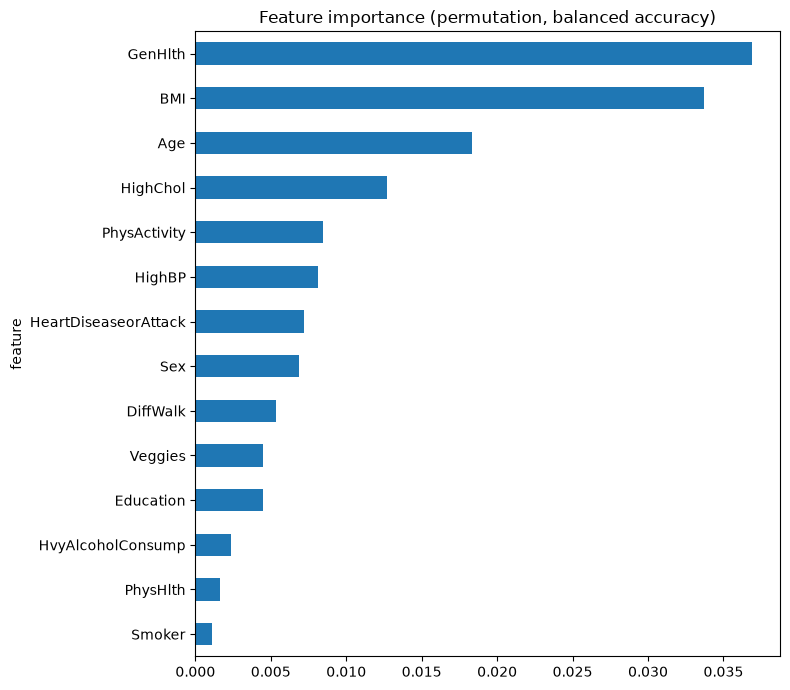

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif

# ---- CONFIG ----
FILE = "Dataset/Diabetes_data_og.csv"   # change to your filename (.xlsx or .csv)
SHEET = 0
TARGET = "Diabetes_012"
SAMPLE = 60000           # rows used for speed; set to None for all rows
# ----------------------

df = pd.read_csv(FILE) if FILE.endswith(".csv") else pd.read_excel(FILE, sheet_name=SHEET)
df = df.dropna(axis=1, how="all").dropna()

if SAMPLE and len(df) > SAMPLE:
    df = df.sample(SAMPLE, random_state=42)

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, class_weight="balanced",
    n_jobs=-1, random_state=42
).fit(X_train, y_train)
print(f"Test accuracy: {rf.score(X_test, y_test):.3f}\n")

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=5, scoring="balanced_accuracy",
    n_jobs=-1, random_state=42
)

result = pd.DataFrame({
    "feature": X.columns,
    "rf_importance": rf.feature_importances_,
    "permutation_importance": perm.importances_mean,
    "mutual_info": mutual_info_classif(X, y, random_state=42),
    "corr_with_target": X.corrwith(y).values,
}).sort_values("permutation_importance", ascending=False)

print(result.round(4).to_string(index=False))
result.to_csv("feature_importance_results.csv", index=False)

result.sort_values("permutation_importance").plot.barh(
    x="feature", y="permutation_importance", legend=False, figsize=(8, 7)
)
plt.title("Feature importance (permutation, balanced accuracy)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()